# Famine early-warning: exploratory data analysis

Covers the **outputs** (FEWS NET Most-Likely projections `ml1`/`ml2` and the SMART soil-moisture trigger
at 80/120/180-observation windows) and the **inputs** feeding them (FEWS current situation, soil moisture,
FAO prices, ACLED conflict, World Bank CPI, admin boundaries). The full column-level data dictionary is in `FEATURES.md`.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
import famine as fm
from famine.plotting import COUNTRY_COLORS, IPC_COLORS, CHANGE_COLORS, set_style, ipc_legend, facet
set_style(); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
data = fm.load_all()

## 1. Inventory

In [2]:
def summarize(name, df):
    dcol = next((c for c in ['date', 'issued', 'year'] if c in df), None)
    return dict(dataset=name, rows=len(df), cols=df.shape[1],
                start=df[dcol].min(), end=df[dcol].max(),
                countries=', '.join(sorted(df['country'].astype(str).unique())),
                n_regions=df['region'].nunique() if 'region' in df else None,
                null_cells=int(df.isna().sum().sum()))
pd.DataFrame([summarize(k, v) for k, v in data.items()]).set_index('dataset')

,rows,cols,start,end,countries,n_regions,null_cells
dataset,,,,,,,
ml1,8687,11,2018-12-01 00:00:00,2026-05-01 00:00:00,"Guatemala, Kenya, Malawi, Nigeria, Uganda",455.0,0
ml2,8056,11,2018-12-01 00:00:00,2026-01-01 00:00:00,"Kenya, Malawi, Nigeria, Uganda",132.0,0
smart_80,4486,16,2019-01-03 00:00:00,2026-07-31 00:00:00,"Kenya, Malawi, Nigeria, Uganda",4.0,1272
smart_120,4486,16,2019-01-03 00:00:00,2026-07-31 00:00:00,"Kenya, Malawi, Nigeria, Uganda",4.0,1912
smart_180,4486,16,2019-01-03 00:00:00,2026-07-31 00:00:00,"Kenya, Malawi, Nigeria, Uganda",4.0,2872
fews,2686,6,2019-02-01 00:00:00,2026-07-01 00:00:00,"Guatemala, Kenya, Malawi, Nigeria, Uganda",459.0,0
soil_moisture,50138,5,2019-01-01 00:00:00,2026-09-02 00:00:00,"Guatemala, Kenya, Malawi, Nigeria, Somalia, Ug...",34.0,0
prices,18032,9,2019-01-01 00:00:00,2026-08-01 00:00:00,"Guatemala, Kenya, Malawi, Nigeria, Somalia, Ug...",50.0,80
conflict_monthly,558,8,2019-01-01 00:00:00,2026-09-01 00:00:00,"Guatemala, Kenya, Malawi, Nigeria, Somalia, Ug...",NaN,0


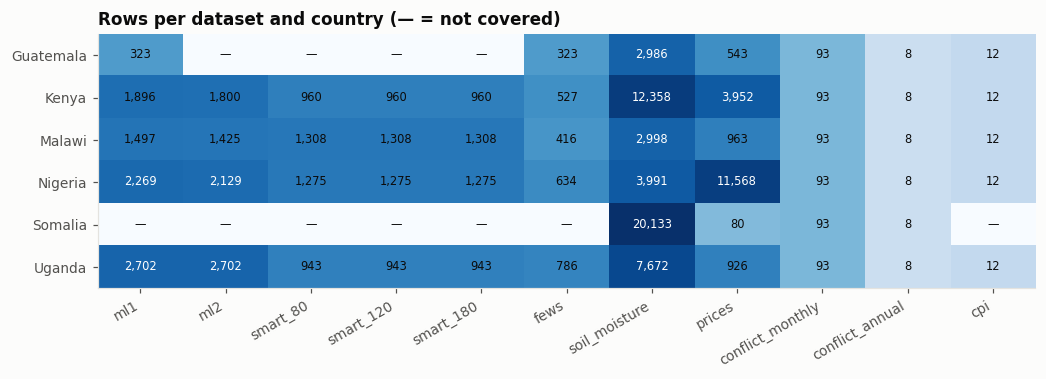

In [3]:
# Country coverage: rows per dataset x country
cov = pd.DataFrame({k: v.groupby(v['country'].astype(str)).size() for k, v in data.items()}).reindex(fm.COUNTRIES).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(11, 3))
ax.imshow(np.log1p(cov.values), cmap='Blues', aspect='auto')
ax.set_xticks(range(cov.shape[1]), cov.columns, rotation=30, ha='right'); ax.set_yticks(range(len(cov)), cov.index)
for (i, j), v in np.ndenumerate(cov.values):
    ax.text(j, i, f'{v:,}' if v else '—', ha='center', va='center', fontsize=7.5, color='#0b0b0b' if v < 2000 else 'white')
ax.grid(False); ax.set_title('Rows per dataset and country (— = not covered)'); plt.show()

**Coverage gaps:** Somalia appears only in soil moisture, prices (80 rows, one series) and conflict, with no IPC
labels or CPI. Guatemala has IPC data only for a single 2018-12 projection and one 2019-02 observation.
SMART covers Kenya, Malawi, Nigeria and Uganda, with one region each.

## 2. Outputs: FEWS NET Most-Likely projections (ml1, ml2)

In [4]:
ml = fm.load_ml_all()
ml.groupby(['horizon', 'country'], observed=True).agg(
    rows=('region', 'size'), zones=('region', 'nunique'), issues=('issued', 'nunique'),
    first_issue=('issued', 'min'), last_issue=('issued', 'max'),
    mean_lead_days=('lead_days', 'mean'), mean_window_days=('window_days', 'mean'),
    share_ipc3plus=('predicted_ipc', lambda s: (s.astype(int) >= 3).mean().round(3))).round(1)

rows  zones  issues first_issue last_issue  mean_lead_days  mean_window_days  share_ipc3plus
horizon country                                                                                                
ml1     Guatemala   323    323       1  2018-12-01 2018-12-01             0.0              62.0             0.1
        Kenya      1896     24      79  2018-12-01 2026-05-01             0.0              76.6             0.3
        Malawi     1497     19      80  2018-12-01 2026-05-01             0.0              76.0             0.2
        Nigeria    2269     49      67  2019-06-01 2026-05-01             0.0              77.2             0.2
        Uganda     2702     41      67  2018-12-01 2024-10-01             0.0              77.6             0.0
ml2     Kenya      1800     24      75  2018-12-01 2026-01-01            76.7             121.7             0.3
        Malawi     1425     19      76  2018-12-01 2026-01-01            76.0             121.8             0.1
        Nigeria    2129     49      63  2019-06-01 2026-01-01            77.2             121.6             0.2
        Uganda     2702     41      67  2018-12-01 2024-10-01            77.6             121.8             0.0

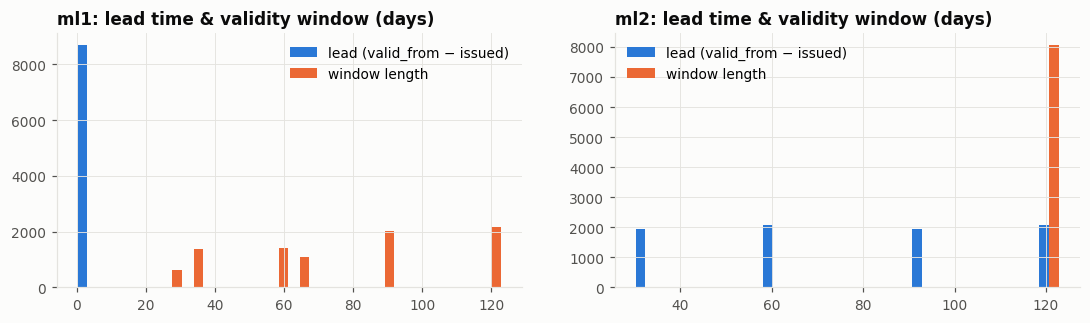

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, (h, g) in zip(axes, ml.groupby('horizon')):
    ax.hist([g['lead_days'], g['window_days']], bins=20, label=['lead (valid_from − issued)', 'window length'], color=['#2a78d6', '#eb6834'], rwidth=0.9)
    ax.set_title(f'{h}: lead time & validity window (days)'); ax.legend()
plt.show()

`ml1` always starts on the issue date (lead 0) and covers 1–4 months. `ml2` starts 1–4 months later, right where the matching ml1 window ends.

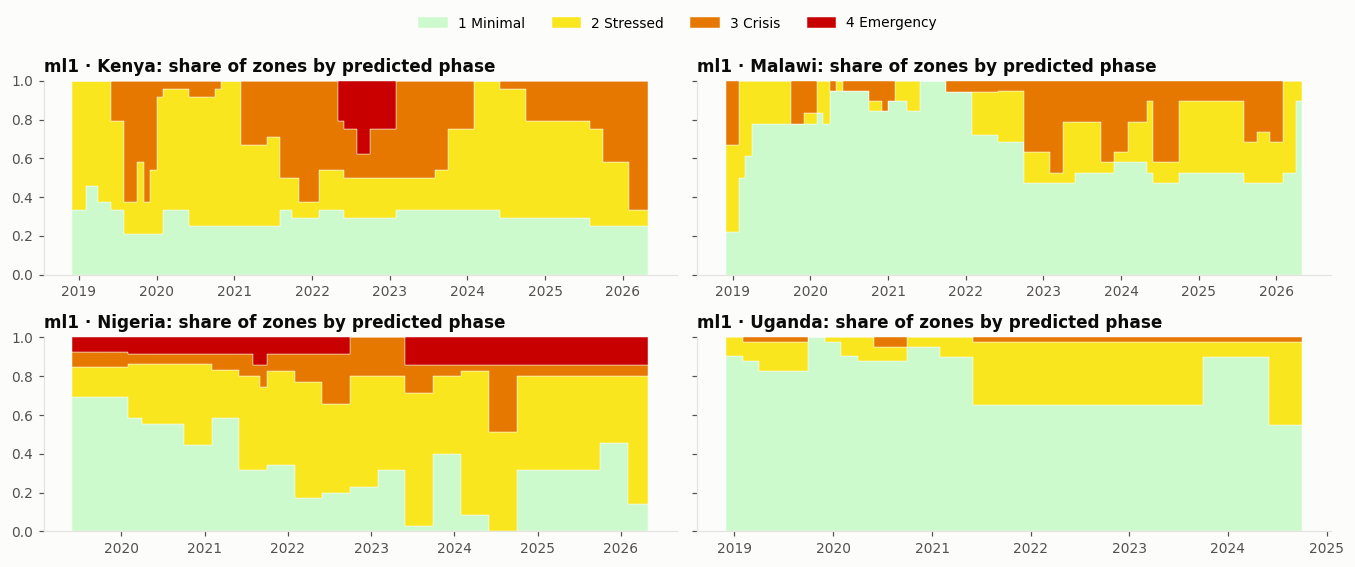

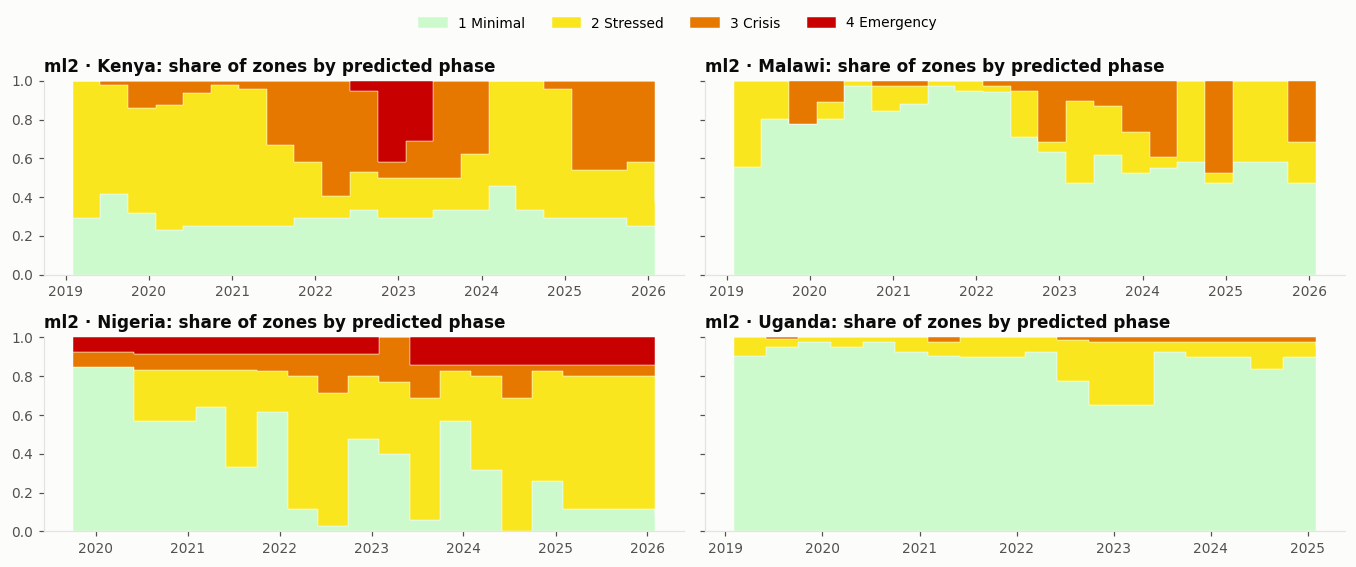

In [6]:
# Share of zones in each predicted IPC phase over time (by valid_from), per country
for h in ['ml1', 'ml2']:
    g = ml[(ml.horizon == h) & (ml.country != 'Guatemala')]
    cs = sorted(g.country.astype(str).unique())
    fig, axs = facet(len(cs), ncols=2, w=6.2, h=2.4, sharey=True)
    for ax, c in zip(axs, cs):
        sh = pd.crosstab(g[g.country == c].valid_from, g[g.country == c].predicted_ipc, normalize='index')
        ax.stackplot(sh.index, sh.T.values, colors=[IPC_COLORS[p] for p in sh.columns], step='post', edgecolor='#fcfcfb', linewidth=0.3)
        ax.set_title(f'{h} · {c}: share of zones by predicted phase'); ax.set_ylim(0, 1); ax.grid(False)
    fig.tight_layout(); ipc_legend(fig, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=4); plt.show()

### 2a. Projection skill against observed FEWS current situation

In [7]:
pairs = {h: fm.ml_vs_observed(h) for h in ['ml1', 'ml2']}
def skill(m):
    p, o = m.predicted_ipc.astype(int), m.ipc.astype(int)
    return pd.Series(dict(pairs=len(m), exact=(p == o).mean(), within_1=((p - o).abs() <= 1).mean(),
        mean_error=(p - o).mean(), over=(p > o).mean(), under=(p < o).mean(),
        ipc3plus_recall=((p >= 3) & (o >= 3)).sum() / max((o >= 3).sum(), 1),
        ipc3plus_precision=((p >= 3) & (o >= 3)).sum() / max((p >= 3).sum(), 1)))
pd.concat({h: m.groupby('country', observed=True).apply(skill, include_groups=False).assign() for h, m in pairs.items()}).round(3)

pairs  exact  within_1  mean_error   over  under  ipc3plus_recall  ipc3plus_precision
    country                                                                                        
ml1 Kenya     480.0  0.910     1.000      -0.006  0.042  0.048            0.862               0.916
    Malawi    374.0  0.939     0.995       0.029  0.045  0.016            0.902               0.807
    Nigeria   576.0  0.953     1.000       0.040  0.043  0.003            1.000               0.968
    Uganda    726.0  0.949     1.000      -0.012  0.019  0.032            0.867               0.929
ml2 Kenya    1776.0  0.817     0.997      -0.036  0.075  0.108            0.738               0.905
    Malawi   1402.0  0.820     0.986      -0.012  0.084  0.096            0.571               0.571
    Nigeria  1824.0  0.794     1.000      -0.038  0.084  0.122            0.894               0.949
    Uganda   2658.0  0.865     0.997      -0.125  0.006  0.128            0.544               0.886

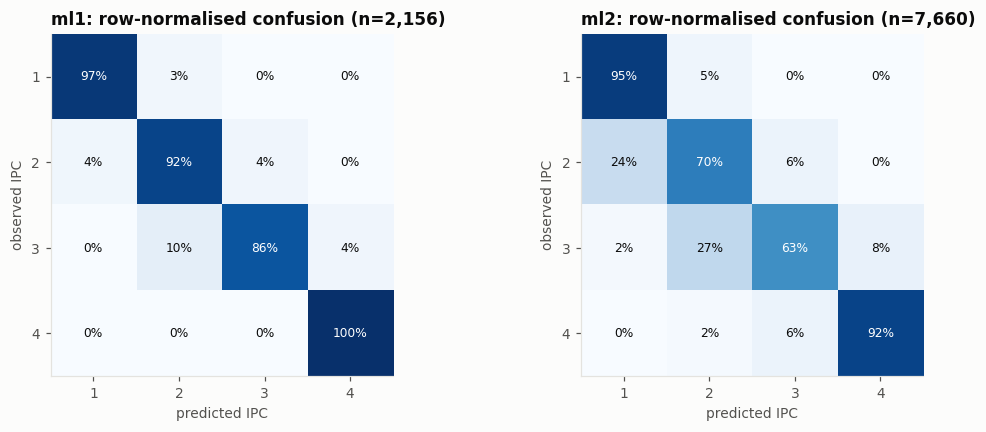

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (h, m) in zip(axes, pairs.items()):
    cm = pd.crosstab(m.ipc.astype(int), m.predicted_ipc.astype(int), normalize='index')
    ax.imshow(cm.values, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
    ax.set_xticks(range(cm.shape[1]), cm.columns); ax.set_yticks(range(cm.shape[0]), cm.index)
    ax.set_xlabel('predicted IPC'); ax.set_ylabel('observed IPC'); ax.set_title(f'{h}: row-normalised confusion (n={len(m):,})')
    for (i, j), v in np.ndenumerate(cm.values):
        ax.text(j, i, f'{v:.0%}', ha='center', va='center', color='white' if v > .5 else '#0b0b0b', fontsize=8)
fig.tight_layout(); plt.show()

In [9]:
# How does ml2 skill degrade with lead time?
m = pairs['ml2'].assign(lead_m=lambda d: (d.lead_days / 30.4).round().astype(int))
m.groupby('lead_m').apply(lambda g: pd.Series(dict(n=len(g), exact=(g.error == 0).mean(), bias=g.error.mean())), include_groups=False).round(3)

,n,exact,bias
lead_m,,,
1,1888.0,0.845,-0.043
2,1995.0,0.842,-0.059
3,1868.0,0.811,-0.070
4,1909.0,0.817,-0.080


In [10]:
# Consistency: when ml1 and ml2 cover the same zone & valid_from, do they agree?
k = ['country', 'region', 'valid_from']
both = ml[ml.horizon == 'ml1'].merge(ml[ml.horizon == 'ml2'], on=k, suffixes=('_ml1', '_ml2'))
both['revision'] = both.predicted_ipc_ml1.astype(int) - both.predicted_ipc_ml2.astype(int)
print(f'{len(both):,} matched zone-periods; agreement {(both.revision == 0).mean():.1%}')
both.revision.value_counts().sort_index().rename('ml1 − ml2 (later revision)')

7,660 matched zone-periods; agreement 84.1%


revision
-2      13
-1     331
 0    6444
 1     850
 2      22
Name: ml1 − ml2 (later revision), dtype: int64

## 3. Outputs: SMART soil-moisture trigger

Each `smart_{w}_day.csv` shares the same base columns (`date, country, region, soil_moisture, raw_price,
real_price_2025`). Only the derived columns change with the window. Behaviour checked against the data:
- `rolling_mean`, `variance`, `rolling_mean_slope` and `smart_coefficient` are null for the first **w−1 observations** of each region, so the window counts observations, not days.
- `triggered` is True **iff `days_above_threshold` > 60**: the coefficient has stayed above `smart_threshold` for more than 60 consecutive calendar days.
- `predicted_change` is `none` when not triggered. When triggered it is `improve` if `rolling_mean_slope` > 0 (soil getting wetter) and `worsen` if the slope is < 0.
- `smart_threshold` is one constant per region × window.

In [11]:
smart = fm.load_smart_all()
smart.groupby(['window', 'region'], observed=True).agg(
    obs=('date', 'size'), start=('date', 'min'), end=('date', 'max'),
    median_gap_days=('date', lambda d: d.diff().dt.days.median()),
    threshold=('smart_threshold', 'first'), coef_median=('smart_coefficient', 'median'),
    share_above=('above_threshold', 'mean'), share_triggered=('triggered', 'mean'),
    n_worsen=('predicted_change', lambda s: (s == 'worsen').sum()),
    n_improve=('predicted_change', lambda s: (s == 'improve').sum())).round(3)

obs      start        end  median_gap_days  threshold  coef_median  share_above  share_triggered  n_worsen  n_improve
window region                                                                                                                                 
80     kenya_mandera2    960 2019-01-06 2026-04-28              3.0      1.311        1.158        0.291            0.194        72        114
       malawi           1308 2019-01-03 2026-07-31              2.0      4.141        2.016        0.232            0.106        69         69
       nigeria          1275 2019-01-03 2026-05-01              2.0      2.520        0.880        0.195            0.147        93         95
       uganda_karamoja   943 2019-01-04 2026-03-31              3.0      1.089        0.959        0.209            0.054         8         43
120    kenya_mandera2    960 2019-01-06 2026-04-28              3.0      1.549        1.196        0.112            0.042        13         27
       malawi           1308 2019-01-03 2026-07-31              2.0      4.669        2.996        0.172            0.113        61         87
       nigeria          1275 2019-01-03 2026-05-01              2.0      3.049        1.268        0.261            0.192       101        144
       uganda_karamoja   943 2019-01-04 2026-03-31              3.0      1.130        0.998        0.187            0.119        45         67
180    kenya_mandera2    960 2019-01-06 2026-04-28              3.0      1.400        1.290        0.238            0.120        57         58
       malawi           1308 2019-01-03 2026-07-31              2.0      5.119        3.395        0.162            0.095        79         45
       nigeria          1275 2019-01-03 2026-05-01              2.0      3.285        1.365        0.295            0.271       184        162
       uganda_karamoja   943 2019-01-04 2026-03-31              3.0      1.098        0.990        0.200            0.130        56         67

In [12]:
# Check the stated rules hold
for w, g in smart.groupby('window'):
    rule_trig = (g.days_above_threshold > 60) == g.triggered
    rule_dir = np.where(~g.triggered, 'none', np.where(g.rolling_mean_slope > 0, 'improve', 'worsen')) == g.predicted_change.astype(str)
    print(f'window {w}: trigger rule holds {rule_trig.mean():.2%}, direction rule holds {rule_dir.mean():.2%}')

window 80: trigger rule holds 100.00%, direction rule holds 100.00%
window 120: trigger rule holds 100.00%, direction rule holds 100.00%
window 180: trigger rule holds 100.00%, direction rule holds 100.00%


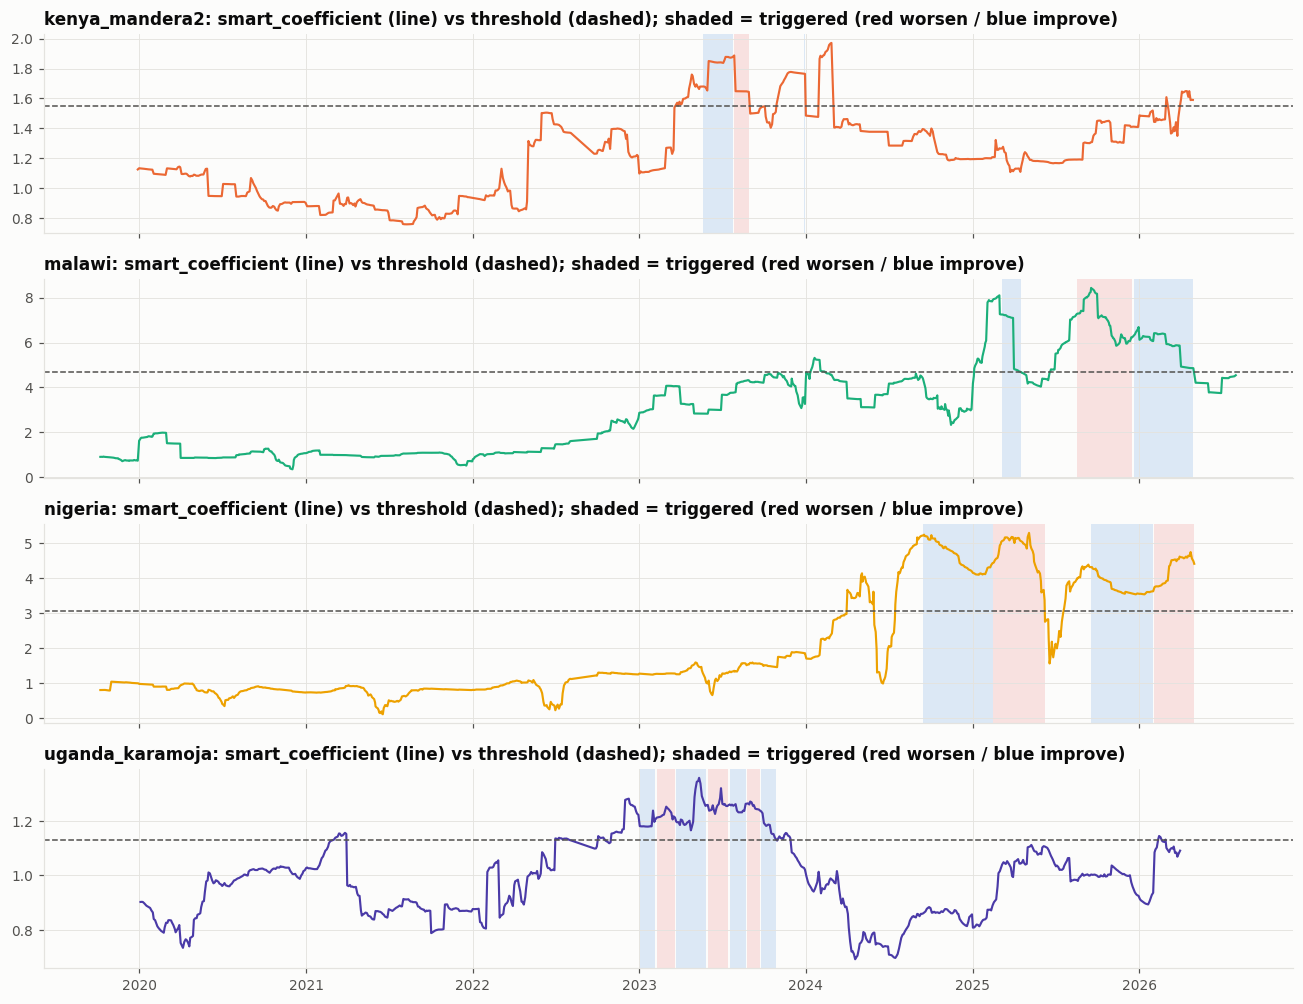

In [13]:
# Coefficient vs threshold through time, triggered periods shaded (120-obs window)
s = smart[smart.window == 120]
regions = list(s.region.cat.categories)
fig, axs = facet(len(regions), ncols=1, w=12, h=2.3, sharex=True)
for ax, r in zip(axs, regions):
    g = s[s.region == r]; c = COUNTRY_COLORS[str(g.country.iloc[0])]
    ax.plot(g.date, g.smart_coefficient, color=c, lw=1.4)
    ax.axhline(g.smart_threshold.iloc[0], color='#52514e', ls='--', lw=1)
    for ch, col in [('worsen', CHANGE_COLORS['worsen']), ('improve', CHANGE_COLORS['improve'])]:
        ax.fill_between(g.date, 0, 1, where=g.predicted_change == ch, color=col, alpha=0.15, transform=ax.get_xaxis_transform(), step='post', lw=0)
    ax.set_title(f'{r}: smart_coefficient (line) vs threshold (dashed); shaded = triggered (red worsen / blue improve)')
fig.tight_layout(); plt.show()

In [14]:
# Trigger episodes (contiguous triggered runs) per region and window
def episodes(g):
    run = (g.triggered != g.triggered.shift()).cumsum()
    e = g[g.triggered].groupby(run).agg(start=('date', 'min'), end=('date', 'max'), change=('predicted_change', 'first'))
    return e.assign(days=(e.end - e.start).dt.days)
ep = smart.groupby(['window', 'region'], observed=True).apply(episodes, include_groups=False).reset_index(level=-1, drop=True).reset_index()
ep.groupby(['window', 'region'], observed=True).agg(episodes=('start', 'size'), median_days=('days', 'median'),
    worsen=('change', lambda s: (s == 'worsen').sum()), improve=('change', lambda s: (s == 'improve').sum()))

episodes  median_days  worsen  improve
window region                                                 
80     kenya_mandera2          3         69.0       2        1
       malawi                  4         66.5       1        3
       nigeria                 2        188.0       0        2
       uganda_karamoja         4         16.0       2        2
120    kenya_mandera2          2         52.0       0        2
       malawi                  2        148.0       1        1
       nigeria                 2        246.0       0        2
       uganda_karamoja         1        301.0       1        0
180    kenya_mandera2          3         64.0       1        2
       malawi                  3         32.0       2        1
       nigeria                 1        701.0       1        0
       uganda_karamoja         1        330.0       1        0

In [15]:
# How often do the three windows agree on a given date?
wide = smart.pivot_table(index=['region', 'date'], columns='window', values='predicted_change', aggfunc='first', observed=True).dropna()
print('all three windows agree:', f'{(wide.nunique(axis=1) == 1).mean():.1%}')
pd.crosstab(wide[80], wide[180], rownames=['80'], colnames=['180'])

all three windows agree: 84.6%


180,improve,none,worsen
80,,,
improve,161,70,90
none,111,3640,172
worsen,60,68,114


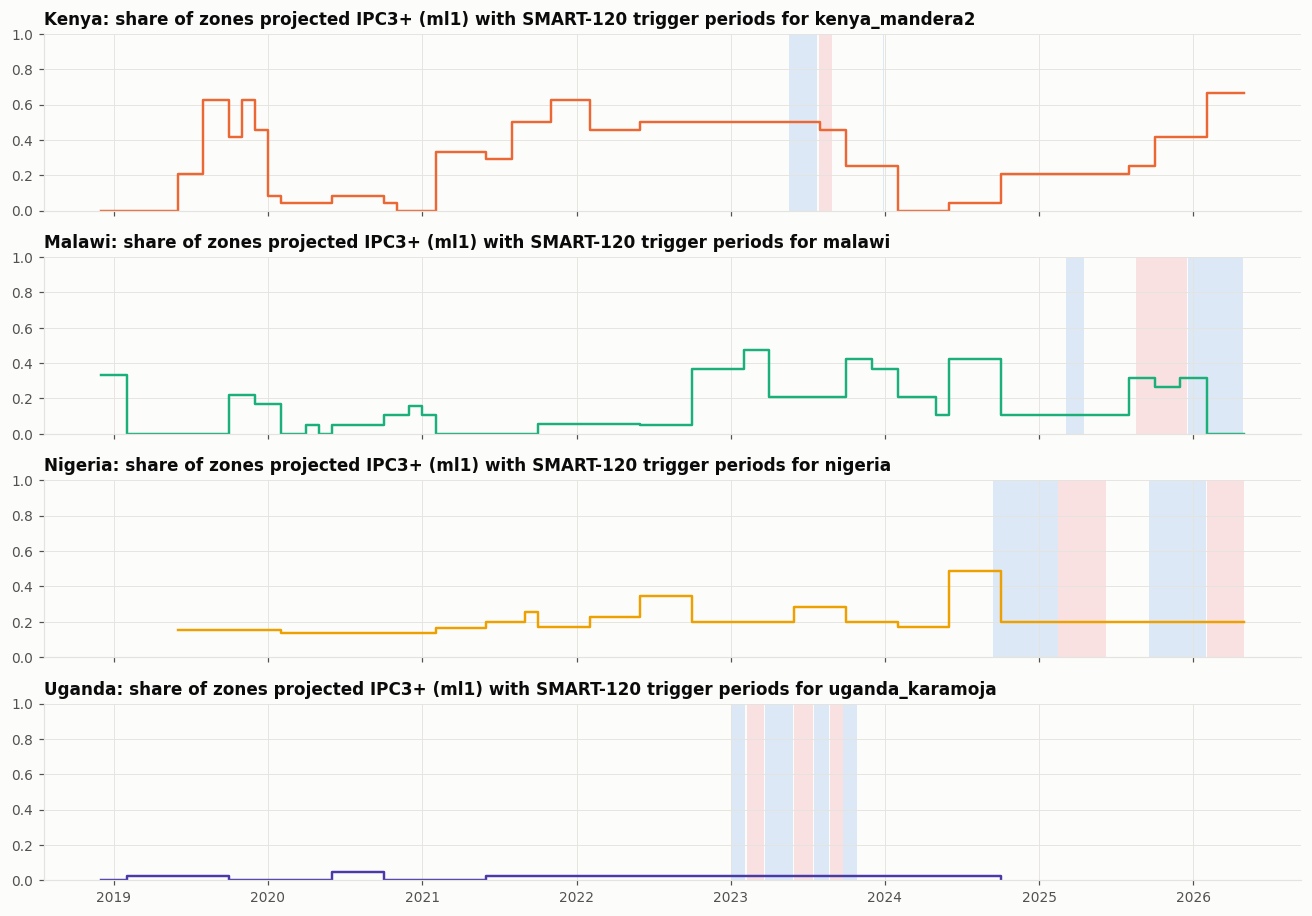

In [16]:
# SMART triggers vs country-level FEWS deterioration: share of zones in projected IPC3+ (ml1) per country
ipc3 = (ml[ml.horizon == 'ml1'].assign(p3=lambda d: d.predicted_ipc.astype(int) >= 3)
        .groupby(['country', 'issued'], observed=True).p3.mean().rename('share_ipc3plus').reset_index())
fig, axs = facet(len(regions), ncols=1, w=12, h=2.1, sharex=True)
for ax, r in zip(axs, regions):
    g = s[s.region == r]; c = str(g.country.iloc[0])
    q = ipc3[ipc3.country == c]
    ax.step(q.issued, q.share_ipc3plus, where='post', color=COUNTRY_COLORS[c])
    ax.fill_between(g.date, 0, 1, where=g.predicted_change == 'worsen', color=CHANGE_COLORS['worsen'], alpha=.15, transform=ax.get_xaxis_transform(), lw=0)
    ax.fill_between(g.date, 0, 1, where=g.predicted_change == 'improve', color=CHANGE_COLORS['improve'], alpha=.15, transform=ax.get_xaxis_transform(), lw=0)
    ax.set_ylim(0, 1); ax.set_title(f'{c}: share of zones projected IPC3+ (ml1) with SMART-120 trigger periods for {r}')
fig.tight_layout(); plt.show()

These are country-level comparisons only. Each SMART region is a single sub-national area, and FEWS livelihood zones do not map onto it directly.

## 4. Inputs

In [17]:
fews = data['fews']
print(fews.groupby(['country', 'area_type'], observed=True).agg(rows=('ipc', 'size'), regions=('region', 'nunique'), dates=('date', 'nunique'), first=('date', 'min'), last=('date', 'max')))
pd.crosstab(fews.country, fews.ipc.astype(int), normalize='index').round(3)

                           rows  regions  dates      first       last
country   area_type                                                  
Guatemala district          323      323      1 2019-02-01 2019-02-01
Kenya     country            23        1     23 2023-04-01 2026-07-01
          livelihood zone   504       24     21 2019-02-01 2026-06-01
Malawi    country            23        1     23 2023-04-01 2026-07-01
          livelihood zone   393       19     21 2019-02-01 2026-06-01
Nigeria   country            23        1     23 2023-04-01 2026-07-01
          livelihood zone   611       49     18 2019-06-01 2026-06-01
Uganda    country            19        1     19 2023-04-01 2026-07-01
          livelihood zone   767       41     19 2019-02-01 2026-06-01


ipc,1,2,3,4
country,,,,
Guatemala,0.771,0.204,0.025,0.000
Kenya,0.290,0.359,0.332,0.019
Malawi,0.659,0.171,0.171,0.000
Nigeria,0.285,0.468,0.131,0.115
Uganda,0.723,0.228,0.050,0.000


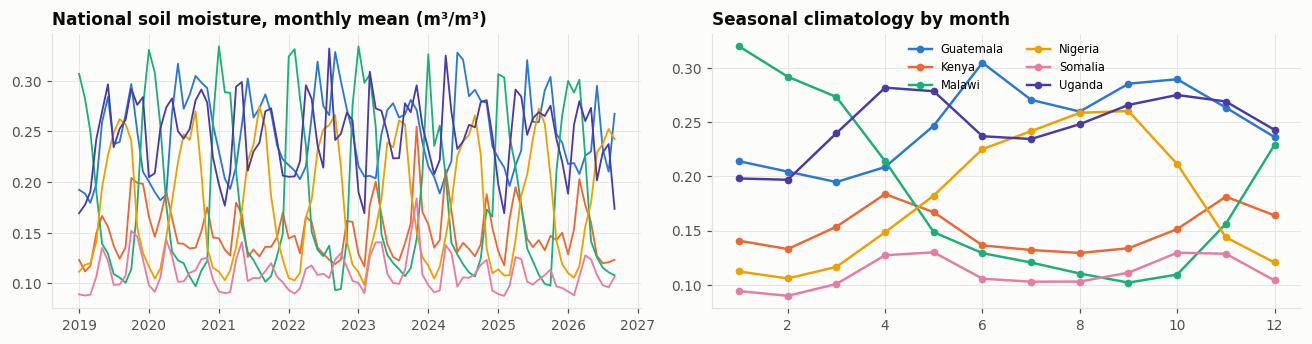

country      Guatemala                   Kenya                                                                                                                              Malawi            \
region       guatemala  national kenya_central kenya_coastal kenya_east kenya_mandera kenya_mandera2 kenya_northeast kenya_nyanza kenya_rift_valley kenya_west  national    malawi  national   
obs           1326.000  1660.000      1006.000      1006.000   1340.000      1334.000       1006.000        1006.000     1116.000          1338.000   1197.000  2009.000  1325.000  1673.000   
median_cells     2.000    16.000         8.000        10.000     45.000        42.000         12.000          42.000        3.000            55.000      4.000   313.000     4.000   155.000   
mean_sm          0.237     0.246         0.227         0.099      0.116         0.121          0.115           0.097        0.289             0.182      0.277     0.151     0.148     0.187   

country        Nigeria            Somalia                                                                                                                                                          \
region        national   nigeria national  somalia somalia_01 somalia_02 somalia_03 somalia_04 somalia_05 somalia_06 somalia_07 somalia_09 somalia_10 somalia_11 somalia_12 somalia_13 somalia_15   
obs           2656.000  1335.000  2009.00  1007.00   1309.000   1307.000   1118.000   1003.000   1340.000   1325.000   1337.000   1006.000   1005.000   1340.000   1005.000   1004.000   1006.000   
median_cells   320.500    12.000   393.00    16.00      1.000     21.000      6.000      2.000     54.000     28.000      4.000      5.000      4.000     10.000      6.000      2.000      9.000   
mean_sm          0.175     0.086     0.11     0.14      0.058      0.089      0.118      0.084      0.101      0.094      0.111      0.059      0.085      0.123      0.138      0.141      0.126   

country                               Uganda                                                                               
region       somalia_16 somalia_18  national uganda_central uganda_eastern uganda_karamoja uganda_northern uganda_western  
obs            1006.000   1006.000  2001.000       1333.000        995.000        1001.000        1339.000       1003.000  
median_cells      4.000      8.000    95.000          7.000          4.000           6.000          24.000          7.000  
mean_sm           0.151      0.128     0.247          0.252          0.273           0.189           0.226          0.217

In [18]:
sm = data['soil_moisture']
nat = sm[sm.region == 'national'].assign(month=lambda d: d.date.dt.month)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for c, g in nat.groupby('country', observed=True):
    g2 = g.set_index('date').soil_moisture.resample('MS').mean()
    axes[0].plot(g2.index, g2, color=COUNTRY_COLORS[c], label=c, lw=1.2)
    clim = g.groupby('month').soil_moisture.mean(); axes[1].plot(clim.index, clim, color=COUNTRY_COLORS[c], marker='o', ms=4, label=c)
axes[0].set_title('National soil moisture, monthly mean (m³/m³)'); axes[1].set_title('Seasonal climatology by month')
axes[1].legend(ncol=2, fontsize=7.5); fig.tight_layout(); plt.show()
sm.groupby(['country', 'region'], observed=True).agg(obs=('date', 'size'), median_cells=('valid_cells', 'median'), mean_sm=('soil_moisture', 'mean')).round(3).T

                      series  markets   rows
country   price_type                        
Guatemala Wholesale        5        2    543
Kenya     Retail           8       18   3748
          Wholesale        2        5    204
Malawi    Retail           3       10    963
Nigeria   Retail          17       13  10125
          Wholesale        6        6   1443
Somalia   Retail           1        1     80
Uganda    Retail           7        1    585
          Wholesale        3        5    341


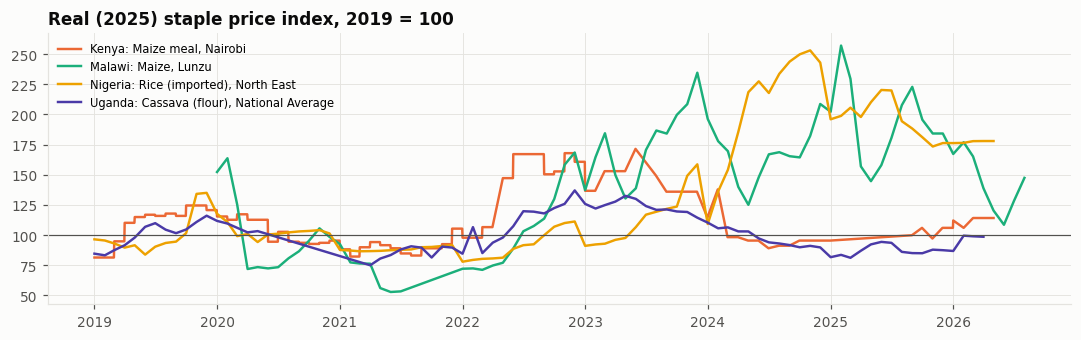

In [19]:
pr = data['prices']
print(pr.groupby(['country', 'price_type'], observed=True).agg(series=('commodity', lambda s: s.nunique()), markets=('region', 'nunique'), rows=('raw_price', 'size')))
# Real price index (first 12 months = 100) for the staple series used by SMART
staples = {'Kenya': ('Nairobi', 'Maize meal'), 'Malawi': ('Lunzu', 'Maize'), 'Nigeria': ('North East', 'Rice (imported)'), 'Uganda': ('National Average', 'Cassava (flour)')}
fig, ax = plt.subplots(figsize=(12, 3.2))
for c, (r, com) in staples.items():
    g = pr[(pr.country == c) & (pr.region == r) & (pr.commodity == com) & (pr.price_type == 'Retail')].set_index('date')[fm.REAL_PRICE].sort_index()
    ax.plot(g.index, 100 * g / g.iloc[:12].mean(), color=COUNTRY_COLORS[c], label=f'{c}: {com}, {r}')
ax.axhline(100, color='#52514e', lw=.8); ax.set_title('Real (2025) staple price index, 2019 = 100'); ax.legend(fontsize=7.5); plt.show()

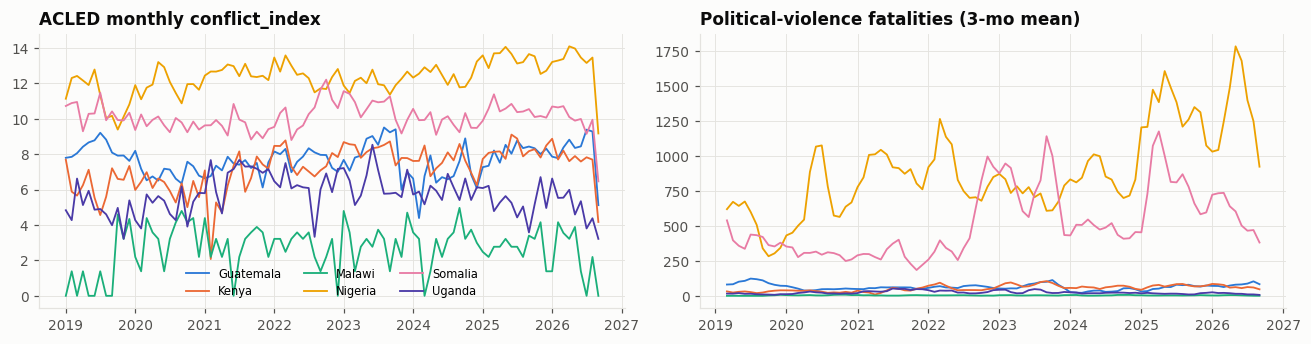

,political_violence_events,political_violence_fatalities,civilian_targeting_events,civilian_targeting_fatalities,demonstration_events,conflict_index
country,,,,,,
Guatemala,0.85,0.91,0.86,0.89,0.23,1.0
Kenya,0.78,0.89,0.78,0.89,0.54,1.0
Malawi,0.75,0.93,0.74,0.93,0.12,1.0
Nigeria,0.77,0.89,0.77,0.92,0.02,1.0
Somalia,0.32,0.75,0.48,0.68,0.06,1.0
Uganda,0.61,0.87,0.69,0.89,0.40,1.0


In [20]:
cf = data['conflict_monthly']
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for c, g in cf.groupby('country', observed=True):
    axes[0].plot(g.date, g.conflict_index, color=COUNTRY_COLORS[c], label=c, lw=1.2)
    axes[1].plot(g.date, g.political_violence_fatalities.rolling(3).mean(), color=COUNTRY_COLORS[c], lw=1.2)
axes[0].set_title('ACLED monthly conflict_index'); axes[1].set_title('Political-violence fatalities (3-mo mean)'); axes[0].legend(ncol=3, fontsize=7.5)
fig.tight_layout(); plt.show()
cf.drop(columns='date').groupby('country', observed=True).corr().round(2).xs('conflict_index', level=1)

In [21]:
data['conflict_annual'].dropna(subset=['index_level'])[['year', 'country', 'conflict_index', 'index_level', 'index_ranking']]

,year,country,conflict_index,index_level,index_ranking
4,2023,Guatemala,13.3762,High,24
5,2024,Guatemala,11.9814,Turbulent,35
6,2025,Guatemala,13.0914,High,17
12,2023,Kenya,13.2167,High,19
13,2024,Kenya,12.5776,High,23
14,2025,Kenya,13.2031,High,24
20,2023,Malawi,7.9402,Low/Inactive,<NA>
21,2024,Malawi,7.8236,Low/Inactive,<NA>
22,2025,Malawi,7.3771,Low/Inactive,58
28,2023,Nigeria,17.0780,Extreme,5


In [22]:
cpi = data['cpi'].pivot(index='year', columns='country', values='cpi')
(cpi.pct_change() * 100).round(1).rename_axis(columns='YoY inflation %')

YoY inflation %,Guatemala,Kenya,Malawi,Nigeria,Uganda
year,,,,,
2014,NaN,NaN,NaN,NaN,NaN
2015,2.4,6.6,21.9,9.0,5.6
2016,4.4,6.3,21.7,15.7,5.7
2017,4.4,8.0,11.5,16.5,5.2
2018,3.8,4.7,12.4,12.1,2.6
2019,3.7,5.2,9.4,11.4,2.9
2020,3.2,5.4,8.6,13.2,3.3
2021,4.3,6.1,9.3,17.0,2.2
2022,6.9,7.7,21.0,18.8,7.2


In [23]:
# Admin boundary coverage and joinability of IPC region names
regs = fm.load_regions()
print(regs.groupby(['country', 'layer']).size().unstack())
keys = set(zip(regs.country, regs.region_key))
fews.assign(joins=[(c, k) in keys for c, k in zip(fews.country.astype(str), fews.region_key)]).groupby(['country', 'area_type'], observed=True).joins.mean().round(3)

layer      admin1  country  districts
country                              
Guatemala      22        1        342
Kenya          47        1        290
Malawi          3        1         28
Nigeria        37        1        774
Somalia        18        1        118
Uganda          4        1        151


country    area_type      
Guatemala  district           0.978
Kenya      country            0.000
           livelihood zone    0.000
Malawi     country            0.000
           livelihood zone    0.000
Nigeria    country            0.000
           livelihood zone    0.000
Uganda     country            0.000
           livelihood zone    0.000
Name: joins, dtype: float64

## 5. Data-quality notes

In [24]:
notes = []
pr_null = pr[pr[fm.REAL_PRICE].isna()]
notes.append(f'prices: {len(pr_null)} rows missing real_price_2025, all in {sorted(pr_null.country.astype(str).unique())} (no CPI for Somalia)')
notes.append(f"prices: raw_price spans {pr.raw_price.min():,.0f}–{pr.raw_price.max():,.0f}. Units vary ({pr.unit.nunique()} units, e.g. NGN/100 kg vs NGN/Kg), so normalise before comparing across series")
z = cf[cf.conflict_index == 0]; notes.append(f'conflict: {len(z)} months with conflict_index == 0 ({sorted(z.country.astype(str).unique())})')
notes.append(f"conflict_annual: index_level/index_ranking only populated for 2023–2025; index_ranking null for Malawi 2023–24")
notes.append(f"soil moisture: region == 'national' and region == '<country>' are distinct series (median valid_cells {sm[sm.region=='national'].valid_cells.median():.0f} vs far fewer), so don't treat them as duplicates")
notes.append(f'fews: area_type == "country" rows (one per country, {len(fews[fews.area_type=="country"])} total, 2023+) have region == country name and no ml1/ml2 counterpart')
notes.append('ml/fews: livelihood-zone names have no geometry in data/regions; only Guatemala districts join (316/323 after accent normalisation)')
notes.append('smart: files labelled *_day use an observation-count window. Observations are irregular (~2–3 day gaps)')
notes.append('dates extend to 2026-09; check whether recent rows are provisional')
print('\n'.join('• ' + n for n in notes))

• prices: 80 rows missing real_price_2025, all in ['Somalia'] (no CPI for Somalia)
• prices: raw_price spans 25–5,040,000. Units vary (20 units, e.g. NGN/100 kg vs NGN/Kg), so normalise before comparing across series
• conflict: 11 months with conflict_index == 0 (['Malawi'])
• conflict_annual: index_level/index_ranking only populated for 2023–2025; index_ranking null for Malawi 2023–24
• soil moisture: region == 'national' and region == '<country>' are distinct series (median valid_cells 163 vs far fewer), so don't treat them as duplicates
• fews: area_type == "country" rows (one per country, 88 total, 2023+) have region == country name and no ml1/ml2 counterpart
• ml/fews: livelihood-zone names have no geometry in data/regions; only Guatemala districts join (316/323 after accent normalisation)
• smart: files labelled *_day use an observation-count window. Observations are irregular (~2–3 day gaps)
• dates extend to 2026-09; check whether recent rows are provisional
